# BÁO CÁO THỰC HÀNH 2 — TRANSFER LEARNING

### Ứng dụng học chuyển giao (VGG16, DenseNet121) để phân loại 37 giống chó, mèo trên bộ dữ liệu Oxford-IIIT Pet

| Nhóm | Học phần | Dữ liệu | Mô hình |
|:---:|:---:|:---:|:---:|
| **Nhóm 10** | Mạng nơ-ron tích chập và học chuyển giao | Oxford-IIIT Pet · 37 lớp | VGG16 (baseline) · DenseNet121 |

> **Kết quả chính.** Nhóm chạy 4 cấu hình (2 mô hình × learning rate 0.01 / 0.001, batch size 16). Mỗi mô hình chọn cấu hình theo validation loss, sau đó mới đánh giá trên test.
> **DenseNet121 (LR 0.001) đạt test accuracy 91.31%**, cao hơn baseline **VGG16 (88.80%)** 2.51 điểm phần trăm.
> Đây là kết quả của một lần chạy với một split và seed 42.

## Mục lục

| Phần I — Đăng ký đề tài | Phần II — Báo cáo |
|---|---|
| 1. Tên đề tài | 11. Dữ liệu mẫu và mô tả |
| 2. Hướng chính | 12. Mã nguồn |
| 3. Người sử dụng và vấn đề | 13. Hướng dẫn cài đặt và chạy |
| 4. Mục tiêu | 14. Demo |
| 5. Dữ liệu | 15. Kết quả so sánh với baseline |
| 6. Phạm vi | 16. Phân tích lỗi và giới hạn |
| 7. Phương pháp | 17. Kết luận |
| 8. Sản phẩm | |
| 9. Đánh giá | |
| 10. Kế hoạch và rủi ro | |

---

# PHẦN I — ĐĂNG KÝ ĐỀ TÀI

## 1. Tên đề tài

> **Ứng dụng học chuyển giao (VGG16, DenseNet121) để phân loại 37 giống chó, mèo trên bộ dữ liệu Oxford-IIIT Pet**

| Thành phần (theo mẫu) | Nội dung |
|---|---|
| Công nghệ / hành động | Học chuyển giao từ mô hình pretrained trên ImageNet |
| Bài toán | Phân loại ảnh: mỗi ảnh thuộc 1 trong 37 giống chó/mèo |
| Phạm vi | Bộ dữ liệu Oxford-IIIT Pet; hai kiến trúc VGG16 và DenseNet121 |

## 2. Hướng chính

**Thị giác máy tính · Transfer Learning**

Dùng VGG16 và DenseNet121 pretrained trên ImageNet, thay lớp phân loại cuối thành 37 lớp và so sánh kết quả trên cùng bộ dữ liệu.

> Phạm vi: thực nghiệm và đánh giá mô hình; chưa triển khai ứng dụng thời gian thực.

## 3. Người sử dụng và vấn đề

| Người sử dụng | Nhu cầu |
|---|---|
| Sinh viên, giảng viên | Học, kiểm tra và đánh giá quy trình transfer learning cho bài toán phân loại ảnh |
| Người xem demo, thuyết trình | Xem quy trình huấn luyện và kết quả so sánh hai mô hình |

**Khó khăn hiện tại:** 37 giống chó/mèo có nhiều giống trông gần giống nhau nên phân biệt bằng mắt có thể khó. Thay vì khởi tạo một mạng mới và học tất cả tham số từ đầu, đề tài dùng lại mô hình đã huấn luyện trên ImageNet và chỉ huấn luyện lớp phân loại cuối.

> Mô hình chỉ dùng để tham khảo trong phạm vi học tập, không thay thế đánh giá của con người.

## 4. Mục tiêu

**Đầu ra cần đạt**

- Pipeline phân loại 37 lớp chạy được với cả VGG16 và DenseNet121 (cùng dữ liệu, cùng tiền xử lý).
- Checkpoint tốt nhất theo validation loss cho mỗi cấu hình và bảng kết quả `results.csv`.
- So sánh DenseNet121 với baseline VGG16, và so sánh learning rate 0.01 với 0.001.

**Chỉ số đo lường**

| Chỉ số | Dùng để |
|---|---|
| Validation loss (cross-entropy) | Chọn checkpoint và chọn cấu hình |
| Validation accuracy | Theo dõi chất lượng trong lúc chọn |
| Test loss, test accuracy | Đánh giá cuối cho cấu hình đã chọn |

> Project không đặt trước một ngưỡng accuracy cần đạt; kết quả được báo cáo đúng như số đo trong `results.csv`.

## 5. Dữ liệu

| Mục (theo mẫu) | Nội dung |
|---|---|
| **Nguồn** | [Oxford-IIIT Pet](https://www.robots.ox.ac.uk/~vgg/data/pets/) |
| **Trường dữ liệu** | Mỗi mẫu gồm **một ảnh** và **nhãn giống** (tên thư mục lớp, 37 giá trị). Project chỉ dùng ảnh và nhãn giống. |
| **Quy mô** | 7,349 ảnh, 37 lớp: train 2,941 · validation 739 · test 3,669 |
| **Cách chia** | Theo ghi nhận của nhóm: train/validation tách phân tầng 80/20 từ split `trainval` chính thức; test giữ split `test` chính thức. Bước chia không nằm trong mã nguồn nên không kiểm chứng độc lập được từ repo. |
| **Quyền sử dụng** | Trang dataset ghi giấy phép [CC BY-SA 4.0](https://creativecommons.org/licenses/by-sa/4.0/); bản quyền ảnh thuộc chủ sở hữu gốc. Dữ liệu không được đưa vào repository (`dataset/` nằm trong `.gitignore`). |
| **Phương án thay thế** | Chưa thử bộ dữ liệu khác. Mã nguồn đọc dữ liệu theo cấu trúc `ImageFolder` (`train/`, `val/`, `test/`, mỗi lớp một thư mục) và lấy số lớp từ số thư mục, nên có thể thay bằng bộ dữ liệu khác có cùng cấu trúc. |

## 6. Phạm vi

**Phần bắt buộc — đã thực hiện**

- Hai mô hình pretrained ImageNet: VGG16 và DenseNet121; thay classifier thành 37 lớp và đóng băng backbone.
- Điều chỉnh siêu tham số: learning rate 0.01 và 0.001 (batch size cố định 16).
- Ghi loss/accuracy theo epoch cho TensorBoard (`src/tensorboard_logger.py`).
- Chọn cấu hình bằng validation; chỉ đánh giá test cho cấu hình đã chọn.

**Phần mở rộng**

| Nội dung | Trạng thái |
|---|---|
| Fine-tune khối đặc trưng cuối (`--fine-tune-last-block`) | Có trong code, **chưa dùng** trong kết quả |
| Batch size 32 | Code hỗ trợ (`--batch-sizes`), **chưa chạy** |
| Nhiều seed hoặc k-fold | Chưa thực hiện |
| Confusion matrix, precision/recall theo lớp | Chưa thực hiện |
| Ứng dụng hoặc API dự đoán | Chưa thực hiện |

## 7. Phương pháp

| Vai trò | Mô hình | Đặc điểm |
|---|---|---|
| **Baseline** | VGG16 pretrained ImageNet | Các tầng tích chập xếp tuần tự; dùng làm mô hình đối chiếu |
| **Giải pháp** | DenseNet121 pretrained ImageNet | Dense block nối và tái sử dụng đặc trưng giữa các tầng |

Hai mô hình dùng **cùng** dữ liệu, tiền xử lý, loss, optimizer, số epoch tối đa và cách chọn cấu hình, để so sánh hai backbone trong cùng điều kiện.

| Bước | Cách thực hiện | File |
|---|---|---|
| Tiền xử lý train | Resize 256 → RandomResizedCrop 224 → RandomHorizontalFlip → chuẩn hoá ImageNet | `src/data_loader.py` |
| Tiền xử lý validation/test | Resize 256 → CenterCrop 224 → chuẩn hoá ImageNet | `src/data_loader.py` |
| Mô hình | Trọng số ImageNet; thay lớp cuối bằng `Linear(…, 37)`; đóng băng các tầng còn lại | `src/vgg16_model.py`, `src/densenet121_model.py` |
| Huấn luyện | CrossEntropyLoss + Adam; tối đa 5 epoch; early stopping patience 3 | `src/main.py`, `src/engine.py` |
| Chọn mô hình | Lưu checkpoint khi validation loss giảm; mỗi kiến trúc chọn cấu hình có validation loss thấp nhất | `src/main.py` |
| Đánh giá | Chạy test một lần cho cấu hình đã chọn | `src/main.py` |

![Sơ đồ quy trình thực nghiệm](../bao_cao_hinh_anh/so_do_quy_trinh.svg)

## 8. Sản phẩm

| Thành phần (theo mẫu) | Trong project |
|---|---|
| Ứng dụng | Chưa có |
| Mô hình / API | Mã huấn luyện và đánh giá trong `src/`. Checkpoint `best_model.pth` được tạo khi chạy và không có trong repository (`*.pth` nằm trong `.gitignore`). Chưa có API dự đoán. |
| Dữ liệu mẫu | Ảnh minh hoạ `bao_cao_hinh_anh/anh_mau_oxford_pet.png`; bộ dữ liệu đầy đủ tải từ trang chính thức |
| Kết quả | `outputs/reduced-experiments/results.csv` (4 cấu hình) |
| Tài liệu | Notebook này, báo cáo HTML, `README.md`, thư mục `docs/`, hình trong `bao_cao_hinh_anh/` |
| Kiểm tra / kiểm thử | `notebooks/check_dataset_duplicates.py` (ảnh trùng giữa các split), `tests/test_tensorboard_logger.py` |

## 9. Đánh giá

| Mục (theo mẫu) | Nội dung |
|---|---|
| **Chỉ số** | Cross-entropy loss và accuracy (số ảnh dự đoán đúng / tổng số ảnh) trên validation và test; số tham số trainable / tổng |
| **Bộ tình huống** | 4 cấu hình: {VGG16, DenseNet121} × learning rate {0.01, 0.001}; batch size 16, tối đa 5 epoch, patience 3, seed 42 |
| **Cách chia dữ liệu** | Train 2,941 ảnh (cập nhật trọng số) · Validation 739 ảnh (chọn checkpoint/cấu hình) · Test 3,669 ảnh (chỉ đánh giá cuối) |
| **So sánh** | DenseNet121 so với baseline VGG16 ở cấu hình được chọn; LR 0.001 so với LR 0.01 trên validation |

## 10. Kế hoạch và rủi ro

### Tiến độ

| Công việc | Trạng thái |
|---|:---:|
| Chuẩn bị và kiểm tra dữ liệu | ✅ Hoàn thành |
| Xây dựng, chạy và so sánh hai mô hình | ✅ Hoàn thành |
| Đánh giá kết quả và hoàn thiện báo cáo | ✅ Hoàn thành |

*Project không ghi mốc ngày cụ thể.*

### Phân công

| STT | Thành viên | Nhiệm vụ | Mức độ hoàn thành |
|:---:|---|---|:---:|
| 1 | Trần Minh Khoa | | |
| 2 | Trần Ngọc Thiện | | |
| 3 | Nguyễn Đức Bình | | |
| 4 | Phạm Quốc Việt | | |
| 5 | Phạm Quốc Bảo | | |
| 6 | Lê Tuấn Hưng | | |

*Cột nhiệm vụ và mức độ hoàn thành do nhóm điền.*

### Phụ thuộc, rủi ro và cách xử lý

| Phụ thuộc / rủi ro | Cách xử lý trong project |
|---|---|
| Dữ liệu phải chuẩn bị sẵn thành `train/val/test` (code không tự chia) | Kiểm tra tên lớp khớp giữa các split; kiểm tra ảnh trùng bằng SHA-256 |
| Tải trọng số pretrained lần đầu cần Internet | Ghi chú trong hướng dẫn cài đặt (mục 13) |
| Thời gian huấn luyện dài khi chạy trên CPU | Tối đa 5 epoch, early stopping patience 3, đóng băng backbone để giảm số tham số cần cập nhật |
| Chọn mô hình bị thiên lệch theo test | Chọn bằng validation; test chỉ chạy cho cấu hình đã chọn |
| Overfitting | Augmentation ở train; theo dõi train-eval so với validation |
| Kết quả thay đổi theo split/seed | Cố định seed 42; ghi rõ đây là kết quả một lần chạy (chưa chạy nhiều seed) |

---

# PHẦN II — BÁO CÁO

Phần này trình bày theo mục “Báo cáo nên có” của mẫu. Vấn đề và phạm vi đã nêu ở mục 3 và 6.

## 11. Dữ liệu mẫu và mô tả

![Một số ảnh trong split test của Oxford-IIIT Pet](../bao_cao_hinh_anh/anh_mau_oxford_pet.png)

*Một số ảnh trong split test của Oxford-IIIT Pet. Tên thư mục lớp được dùng làm nhãn; ba split phải có cùng tên và thứ tự lớp để chỉ số nhãn nhất quán.*

| Split | Số ảnh | Ảnh mỗi lớp | Vai trò |
|---|---:|---:|---|
| Train | 2,941 | 74–80 | Cập nhật trọng số mô hình |
| Validation | 739 | 19–20 | Đánh giá sau mỗi epoch; chọn checkpoint và cấu hình theo validation loss thấp nhất |
| Test | 3,669 | 88–100 | Chỉ đánh giá cấu hình đã chọn bằng validation |

![Số lượng ảnh trong từng split](../bao_cao_hinh_anh/phan_bo_dataset.png)

**Kiểm tra chất lượng dữ liệu** (theo `docs/data_model_validation.md`)

- Đã quét ảnh trong cả ba split: không phát hiện file ảnh không đọc được.
- Script SHA-256 `notebooks/check_dataset_duplicates.py` không tìm thấy ảnh byte-identical giữa các split. Cách này không phát hiện ảnh đã đổi định dạng/nén lại hoặc ảnh gần giống.

**Tiền xử lý ảnh** (`src/data_loader.py`)

| Split | Phép biến đổi | Lý do |
|---|---|---|
| Train | Resize 256 → RandomResizedCrop 224 → RandomHorizontalFlip → ToTensor → Normalize | Tăng đa dạng ảnh khi học |
| Train-eval / Validation / Test | Resize 256 → CenterCrop 224 → ToTensor → Normalize | Đánh giá ổn định, không có biến đổi ngẫu nhiên |

Chuẩn hoá theo thống kê ImageNet: `mean = (0.485, 0.456, 0.406)`, `std = (0.229, 0.224, 0.225)`.

### Kiểm tra dữ liệu bằng code

Ô đầu tiên chỉ xác định đường dẫn của project. Các ô có ghi chú *cần `dataset/`* chỉ chạy được khi đã có dữ liệu (dữ liệu không có trong repository); nếu chưa có, ô sẽ in thông báo và bỏ qua.

In [1]:
# Xác định thư mục gốc của project, dù notebook được mở từ notebooks/ hay từ thư mục repo.
from pathlib import Path
import sys

ROOT = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / "src" / "main.py").is_file()),
    None,
)
if ROOT is None:
    raise FileNotFoundError("Không tìm thấy src/main.py; hãy mở notebook trong repo BAI_E2.")

DATA_DIR = ROOT / "dataset"
RESULTS_PATH = ROOT / "outputs" / "reduced-experiments" / "results.csv"
HAS_DATASET = all((DATA_DIR / split).is_dir() for split in ("train", "val", "test"))

src_path = str(ROOT / "src")
if src_path not in sys.path:
    sys.path.insert(0, src_path)

print("Project       :", ROOT.name)
print("File kết quả  :", RESULTS_PATH.relative_to(ROOT).as_posix())

Project       : BAI_E2
File kết quả  : outputs/reduced-experiments/results.csv


In [ ]:
# (cần dataset/) Kiểm tra số ảnh, số lớp và tính nhất quán tên lớp giữa các split.
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

if not HAS_DATASET:
    print("Bỏ qua: chưa có dataset/train, dataset/val, dataset/test. Xem mục 13.2 để chuẩn bị dữ liệu.")
else:
    split_classes, split_counts = {}, {}
    for split in ("train", "val", "test"):
        split_dir = DATA_DIR / split
        classes = sorted(path.name for path in split_dir.iterdir() if path.is_dir())
        split_classes[split] = classes
        split_counts[split] = sum(
            1 for path in split_dir.rglob("*")
            if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS
        )
        print(f"{split:>5}: {split_counts[split]:>5} ảnh | {len(classes):>2} lớp")

    if not (split_classes["train"] == split_classes["val"] == split_classes["test"]):
        raise ValueError("Tên lớp giữa train, val và test không đồng nhất.")
    print("Ba split có cùng danh sách lớp; số lớp =", len(split_classes["train"]))

## 12. Mã nguồn

| File | Vai trò |
|---|---|
| [`src/data_loader.py`](../src/data_loader.py) | Đọc ảnh theo `ImageFolder`, augmentation, tạo DataLoader cho train / train-eval / validation / test; kiểm tra tên lớp giữa các split |
| [`src/vgg16_model.py`](../src/vgg16_model.py) | Khởi tạo VGG16 pretrained, thay classifier cuối, đóng băng backbone |
| [`src/densenet121_model.py`](../src/densenet121_model.py) | Khởi tạo DenseNet121 pretrained, thay classifier, đóng băng backbone |
| [`src/models.py`](../src/models.py) | `build_model()` chọn mô hình theo tên; `count_parameters()` đếm tham số |
| [`src/engine.py`](../src/engine.py) | Train một epoch và đánh giá (loss, accuracy) |
| [`src/main.py`](../src/main.py) | Đọc tham số dòng lệnh, chạy các cấu hình, early stopping, lưu checkpoint, chọn cấu hình bằng validation, đánh giá test, ghi `results.csv` |
| [`src/tensorboard_logger.py`](../src/tensorboard_logger.py) | Ghi loss/accuracy và siêu tham số vào TensorBoard |
| [`notebooks/check_dataset_duplicates.py`](check_dataset_duplicates.py) | Tìm ảnh trùng byte-identical giữa các split bằng SHA-256 |
| [`tests/test_tensorboard_logger.py`](../tests/test_tensorboard_logger.py) | Kiểm thử các tag TensorBoard được ghi |

**Thay classifier và đóng băng backbone**

```python
# src/vgg16_model.py
model = models.vgg16(weights=models.VGG16_Weights.DEFAULT)
in_features = model.classifier[6].in_features
model.classifier[6] = nn.Linear(in_features, num_classes)
for parameter in model.features.parameters():
    parameter.requires_grad = False
for parameter in model.classifier[:6].parameters():
    parameter.requires_grad = False

# src/densenet121_model.py
model = models.densenet121(weights=models.DenseNet121_Weights.DEFAULT)
in_features = model.classifier.in_features
model.classifier = nn.Linear(in_features, num_classes)
for parameter in model.features.parameters():
    parameter.requires_grad = False
```

**Một bước huấn luyện** (`src/engine.py`) — khi đánh giá validation/test, optimizer không được truyền vào nên trọng số không bị cập nhật:

```python
logits = model(images)
loss = criterion(logits, labels)
loss.backward()
optimizer.step()
```

**Chọn cấu hình bằng validation rồi mới test** (`src/main.py`):

```python
selected_result = min(model_results, key=lambda result: float(result["best_validation_loss"]))
selected_result["selected_by_validation"] = True
evaluate_selected_checkpoint(selected_result, args, device, expected_classes)
```

| Mô hình | Tham số trainable | Tổng tham số |
|---|---:|---:|
| VGG16 | 151,589 | 134,412,133 |
| DenseNet121 | 37,925 | 6,991,781 |

## 13. Hướng dẫn cài đặt và chạy

Các lệnh chạy từ thư mục gốc của repository.

### 13.1 Tạo môi trường

Thư viện chính trong `requirements.txt`: `torch`, `torchvision`, `tensorboard`, `Pillow`. Để mở notebook này cần thêm `notebook` và `matplotlib`. Lần đầu tải trọng số pretrained cần Internet.

**Windows (PowerShell)**

```powershell
python -m venv .venv
.\.venv\Scripts\Activate.ps1
python -m pip install -r requirements.txt
python -m pip install notebook matplotlib
```

**macOS / Linux**

```bash
python3 -m venv .venv
source .venv/bin/activate
python -m pip install -r requirements.txt
python -m pip install notebook matplotlib
```

### 13.2 Chuẩn bị dữ liệu

Tải Oxford-IIIT Pet từ [trang chính thức](https://www.robots.ox.ac.uk/~vgg/data/pets/) và sắp xếp theo cấu trúc dưới đây (mã nguồn không tự chia dữ liệu). Ba split phải có cùng 37 thư mục lớp.

```text
dataset/
├── train/<tên_giống>/*.jpg
├── val/<tên_giống>/*.jpg
└── test/<tên_giống>/*.jpg
```

Kiểm tra ảnh trùng giữa các split:

```bash
python notebooks/check_dataset_duplicates.py --data-dir dataset
```

### 13.3 Chạy lại 4 cấu hình trong báo cáo

```bash
python src/main.py --data-dir dataset --epochs 5 --patience 3 --batch-size 16 --tune --learning-rates 0.01 0.001 --batch-sizes 16 --seed 42 --output-dir outputs/reproduced
```

> Nếu bỏ `--batch-sizes 16`, chế độ `--tune` dùng mặc định batch size 16 và 32 (8 lần huấn luyện). Nên dùng thư mục output mới để không ghi thêm dòng vào `outputs/reduced-experiments/results.csv` hiện có. Xem toàn bộ tùy chọn bằng `python src/main.py --help`.

### 13.4 Xem TensorBoard

```bash
python -m tensorboard.main --logdir outputs/reproduced
```

Mở địa chỉ được in ra (thường là `http://localhost:6006`). Các tag: `Loss/train`, `Loss/train_eval`, `Loss/validation`, `Accuracy/train`, `Accuracy/train_eval`, `Accuracy/validation`; `Loss/test`, `Accuracy/test` chỉ có ở cấu hình được chọn.

> Repository hiện chỉ có `results.csv`, chưa có event log TensorBoard và checkpoint; cần chạy thí nghiệm để tạo.

### 13.5 Chạy kiểm thử

```bash
python -m unittest discover -s tests
```

## 14. Demo

Demo dựa trên những gì project đã có:

1. **Nạp một batch thật** bằng `create_dataloaders` của project (ô code bên dưới, cần `dataset/`).
2. **Đọc `results.csv` và vẽ biểu đồ so sánh** (mục 15, chạy được ngay vì CSV có trong repository).
3. **Huấn luyện nhanh 1 epoch** bằng lệnh của project để trình bày pipeline:

```bash
python src/main.py --data-dir dataset --models densenet121 --epochs 1 --batch-size 16 --learning-rate 0.001 --output-dir outputs/demo-densenet
```

Kết quả lần demo 1 epoch nhóm đã chạy trước đó (DenseNet121, LR 0.001, batch size 16):

![Kết quả demo DenseNet121 một epoch](../bao_cao_hinh_anh/ket_qua_demo_1_epoch.png)

> Đây là **demo 1 epoch cũ** dùng để kiểm tra pipeline, **không phải kết quả cuối**. Kết quả cuối ở mục 15.

In [ ]:
# (cần dataset/) Demo: dùng chính DataLoader của project để nạp một batch ảnh.
if not HAS_DATASET:
    print("Bỏ qua: chưa có dataset/. Xem mục 13.2 để chuẩn bị dữ liệu.")
else:
    from data_loader import create_dataloaders

    train_loader, train_eval_loader, val_loader, test_loader, class_names = create_dataloaders(
        DATA_DIR, batch_size=16, num_workers=0, seed=42
    )
    images, labels = next(iter(train_loader))
    print("Số lớp         :", len(class_names))
    print("Shape batch ảnh:", tuple(images.shape))  # (16, 3, 224, 224)
    print("Shape nhãn     :", tuple(labels.shape))  # (16,)
    print("Một vài nhãn   :", [class_names[index] for index in labels[:5].tolist()])

## 15. Kết quả so sánh với baseline

Số liệu được đọc trực tiếp từ `outputs/reduced-experiments/results.csv`. Chỉ cấu hình được chọn theo validation mới có số đo test.

In [2]:
import csv
from IPython.display import Markdown, display

NAMES = {"vgg16": "VGG16", "densenet121": "DenseNet121"}

with RESULTS_PATH.open("r", encoding="utf-8-sig", newline="") as results_file:
    results = list(csv.DictReader(results_file))


def is_selected(row):
    return row["selected_by_validation"].lower() == "true"


def pct(value):
    return f"{float(value) * 100:.2f}%" if value else "—"


def num(value):
    return f"{float(value):.4f}" if value else "—"


lines = [
    "| Mô hình | LR | Batch | Epoch tốt nhất / đã chạy | Val loss ↓ | Val acc ↑ | Test loss | Test acc | Chọn theo val |",
    "|---|---:|---:|:---:|---:|---:|---:|---:|:---:|",
]
for row in results:
    lines.append(
        f"| {NAMES[row['model']]} | {float(row['learning_rate']):g} | {row['batch_size']} "
        f"| {row['best_epoch']} / {row['epochs_completed']} | {num(row['best_validation_loss'])} "
        f"| {pct(row['validation_accuracy_at_best_loss'])} | {num(row['test_loss'])} "
        f"| {pct(row['test_accuracy'])} | {'✅' if is_selected(row) else '—'} |"
    )
display(Markdown("\n".join(lines)))

| Mô hình | LR | Batch | Epoch tốt nhất / đã chạy | Val loss ↓ | Val acc ↑ | Test loss | Test acc | Chọn theo val |
|---|---:|---:|:---:|---:|---:|---:|---:|:---:|
| VGG16 | 0.01 | 16 | 4 / 5 | 1.6225 | 87.96% | — | — | — |
| VGG16 | 0.001 | 16 | 4 / 5 | 0.2831 | 91.34% | 0.3450 | 88.80% | ✅ |
| DenseNet121 | 0.01 | 16 | 1 / 4 | 0.4766 | 86.60% | — | — | — |
| DenseNet121 | 0.001 | 16 | 4 / 5 | 0.2767 | 91.88% | 0.3236 | 91.31% | ✅ |

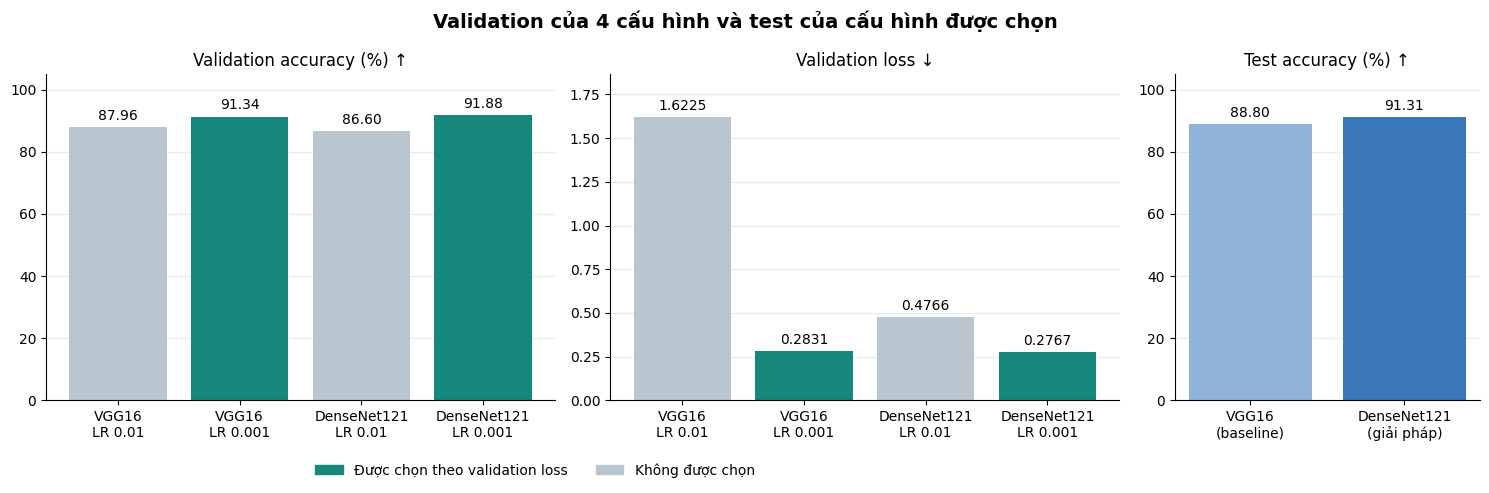

In [3]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
SELECTED, OTHER = "#16877b", "#b9c5cf"

labels = [f"{NAMES[row['model']]}\nLR {float(row['learning_rate']):g}" for row in results]
colors = [SELECTED if is_selected(row) else OTHER for row in results]
validation_accuracy = [float(row["validation_accuracy_at_best_loss"]) * 100 for row in results]
validation_loss = [float(row["best_validation_loss"]) for row in results]
chosen = [row for row in results if is_selected(row)]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.8), gridspec_kw={"width_ratios": [4, 4, 2.4]})
fig.suptitle("Validation của 4 cấu hình và test của cấu hình được chọn", fontsize=14, fontweight="bold")

bars = axes[0].bar(labels, validation_accuracy, color=colors)
axes[0].set_title("Validation accuracy (%) ↑")
axes[0].set_ylim(0, 105)
axes[0].bar_label(bars, fmt="%.2f", padding=3)

bars = axes[1].bar(labels, validation_loss, color=colors)
axes[1].set_title("Validation loss ↓")
axes[1].set_ylim(0, max(validation_loss) * 1.15)
axes[1].bar_label(bars, fmt="%.4f", padding=3)

test_labels = [NAMES[row["model"]] + ("\n(baseline)" if row["model"] == "vgg16" else "\n(giải pháp)") for row in chosen]
test_accuracy = [float(row["test_accuracy"]) * 100 for row in chosen]
bars = axes[2].bar(test_labels, test_accuracy, color=["#8fb3d9" if row["model"] == "vgg16" else "#3977b8" for row in chosen])
axes[2].set_title("Test accuracy (%) ↑")
axes[2].set_ylim(0, 105)
axes[2].bar_label(bars, fmt="%.2f", padding=3)

for axis in axes:
    axis.grid(axis="y", alpha=0.25)
    axis.set_axisbelow(True)
fig.legend(
    handles=[Patch(color=SELECTED, label="Được chọn theo validation loss"), Patch(color=OTHER, label="Không được chọn")],
    loc="lower center", ncol=2, frameon=False, bbox_to_anchor=(0.36, -0.02),
)
fig.tight_layout(rect=(0, 0.05, 1, 1))
plt.show()

In [4]:
# So sánh trực tiếp giải pháp (DenseNet121) với baseline (VGG16) ở cấu hình được chọn.
baseline = next(row for row in chosen if row["model"] == "vgg16")
proposed = next(row for row in chosen if row["model"] == "densenet121")

METRICS = (
    ("Validation loss ↓", "best_validation_loss", "loss"),
    ("Validation accuracy ↑", "validation_accuracy_at_best_loss", "acc"),
    ("Test loss ↓", "test_loss", "loss"),
    ("Test accuracy ↑", "test_accuracy", "acc"),
)
lines = [
    f"| Chỉ số (LR {float(baseline['learning_rate']):g}, batch {baseline['batch_size']}) | VGG16 (baseline) | DenseNet121 | Chênh lệch |",
    "|---|---:|---:|---:|",
]
for label, key, kind in METRICS:
    base, new = float(baseline[key]), float(proposed[key])
    if kind == "acc":
        lines.append(f"| {label} | {base * 100:.2f}% | {new * 100:.2f}% | {(new - base) * 100:+.2f} điểm % |")
    else:
        lines.append(f"| {label} | {base:.4f} | {new:.4f} | {new - base:+.4f} |")
display(Markdown("\n".join(lines)))

| Chỉ số (LR 0.001, batch 16) | VGG16 (baseline) | DenseNet121 | Chênh lệch |
|---|---:|---:|---:|
| Validation loss ↓ | 0.2831 | 0.2767 | -0.0063 |
| Validation accuracy ↑ | 91.34% | 91.88% | +0.54 điểm % |
| Test loss ↓ | 0.3450 | 0.3236 | -0.0213 |
| Test accuracy ↑ | 88.80% | 91.31% | +2.51 điểm % |

**Nhận xét** (chỉ dựa trên các số đo ở trên)

- Ở cấu hình được chọn (LR 0.001, batch size 16), DenseNet121 tốt hơn baseline VGG16 ở cả bốn chỉ số: test accuracy **+2.51 điểm phần trăm**, test loss −0.0213, validation accuracy +0.54 điểm phần trăm, validation loss −0.0063.
- DenseNet121 có ít tham số hơn: tổng 6,991,781 so với 134,412,133; trainable 37,925 so với 151,589. Project chưa đo thời gian chạy và bộ nhớ, nên không kết luận mô hình nào chạy nhanh hơn.
- Cả hai mô hình đều chọn LR 0.001 vì validation loss thấp hơn LR 0.01.
- Kết luận chỉ áp dụng cho một split, seed 42 và các cấu hình đã thử.

## 16. Phân tích lỗi và giới hạn

Project không lưu dự đoán theo từng ảnh, nên **chưa có** confusion matrix hay phân tích lỗi theo từng giống. Phân tích dưới đây chỉ dựa trên số liệu trong `results.csv`.

In [5]:
N_TEST = 3669  # số ảnh test (mục 11)

lines = [
    "| Mô hình (cấu hình được chọn) | Train-eval acc | Val acc | Train-eval − val | Test acc | Val − test | Ảnh test dự đoán sai |",
    "|---|---:|---:|---:|---:|---:|---:|",
]
for row in chosen:
    train_eval = float(row["train_eval_accuracy_at_best_loss"])
    validation = float(row["validation_accuracy_at_best_loss"])
    test = float(row["test_accuracy"])
    wrong = round((1 - test) * N_TEST)
    lines.append(
        f"| {NAMES[row['model']]} | {train_eval * 100:.2f}% | {validation * 100:.2f}% "
        f"| {(train_eval - validation) * 100:.2f} điểm % | {test * 100:.2f}% "
        f"| {(validation - test) * 100:.2f} điểm % | {wrong:,} / {N_TEST:,} ({(1 - test) * 100:.2f}%) |"
    )
display(Markdown("\n".join(lines)))

| Mô hình (cấu hình được chọn) | Train-eval acc | Val acc | Train-eval − val | Test acc | Val − test | Ảnh test dự đoán sai |
|---|---:|---:|---:|---:|---:|---:|
| VGG16 | 95.14% | 91.34% | 3.80 điểm % | 88.80% | 2.54 điểm % | 411 / 3,669 (11.20%) |
| DenseNet121 | 95.95% | 91.88% | 4.07 điểm % | 91.31% | 0.58 điểm % | 319 / 3,669 (8.69%) |

### Phân tích lỗi

1. **Lỗi trên test:** VGG16 dự đoán sai 411 / 3,669 ảnh (11.20%); DenseNet121 sai 319 / 3,669 ảnh (8.69%).
2. **Khoảng cách train-eval và validation:** 3.80 điểm phần trăm (VGG16) và 4.07 điểm phần trăm (DenseNet121); train-eval loss cũng thấp hơn validation loss ở cả hai mô hình. Đây là generalization gap cần theo dõi; một split và một seed chưa đủ để khẳng định mô hình có hay không overfit.
3. **Từ validation sang test:** accuracy giảm 2.54 điểm phần trăm với VGG16 và 0.58 điểm phần trăm với DenseNet121. Project chưa phân tích nguyên nhân của chênh lệch này.
4. **Learning rate 0.01:** VGG16 có validation loss 1.6225 (so với 0.2831 ở LR 0.001) dù validation accuracy vẫn là 87.96%. DenseNet121 đạt validation loss tốt nhất ngay epoch 1 rồi dừng sớm ở epoch 4 vì không cải thiện trong 3 epoch. Vì vậy chọn theo validation loss đã loại cả hai cấu hình LR 0.01.

### Giới hạn

| Giới hạn | Hướng tiếp tục |
|---|---|
| Một seed (42), một split | Chạy thêm seed hoặc k-fold để đánh giá độ ổn định |
| Batch size chỉ có 16 | Thử batch size 32 (code đã hỗ trợ) |
| Tối đa 5 epoch, chạy trên CPU; chưa đo thời gian/bộ nhớ từng mô hình | Đo thời gian và tài nguyên khi so sánh |
| Chưa có confusion matrix, precision/recall theo lớp | Lưu dự đoán theo ảnh để phân tích các giống hay bị nhầm |
| SHA-256 chỉ phát hiện ảnh trùng byte-identical | Kiểm tra thêm ảnh gần giống |
| Bước chia train/validation không có trong mã nguồn | Đưa bước chia vào code để kiểm chứng lại được |
| Repository chưa có event log TensorBoard và checkpoint | Chạy lại thí nghiệm theo mục 13 để tạo |

## 17. Kết luận

Nhóm đã xây dựng pipeline phân loại 37 giống chó/mèo bằng transfer learning: kiểm tra split dữ liệu, tiền xử lý ảnh, augmentation chỉ ở train, thay classifier và đóng băng backbone, huấn luyện bằng CrossEntropyLoss + Adam, chọn checkpoint và cấu hình theo validation loss, rồi mới đánh giá test.

Trong 4 cấu hình đã chạy, **DenseNet121 (LR 0.001, batch size 16) đạt test accuracy 91.31%**, cao hơn baseline **VGG16 (88.80%)** 2.51 điểm phần trăm. Kết luận chỉ phản ánh split, seed và cấu hình đã thử; cần thêm batch size, seed và lần chạy để đánh giá độ ổn định.

### Tài liệu liên quan trong project

- [`README.md`](../README.md) — tổng quan và hướng dẫn chạy
- [`bao_cao_thuc_hanh_2_transfer_learning.html`](bao_cao_thuc_hanh_2_transfer_learning.html) — báo cáo dạng trang web
- [`docs/data_model_validation.md`](../docs/data_model_validation.md) — kiểm tra dữ liệu và mô hình
- [`docs/model_analysis.md`](../docs/model_analysis.md) — phân tích mô hình
- [`docs/lab2_presentation_report.md`](../docs/lab2_presentation_report.md) — báo cáo thuyết trình
- [`docs/lab2_requirements_checklist.md`](../docs/lab2_requirements_checklist.md) — checklist yêu cầu Thực hành 2